## delete everything the setup created colab

In [ ]:
import os
import shutil
from pathlib import Path

BASE_DIR = Path("/content")

# Never touch a mounted Google Drive: deleting it removes your real Drive files.
KEEP = {"drive"}

# Leave the working directory first, since /content/notebooks gets deleted.
os.chdir(BASE_DIR)

for item in BASE_DIR.iterdir():
    if item.name in KEEP:
        print("Skipped:", item)
        continue

    try:
        if item.is_symlink() or item.is_file():
            item.unlink()
            print("Deleted file:", item)
        elif item.is_dir():
            shutil.rmtree(item, ignore_errors=True)
            print("Deleted folder:", item)
    except Exception as e:
        print(f"Failed to delete {item}: {e}")

print("Cleanup complete.")

## this to upload data to colab and install requerments colab

In [ ]:
import os
import re
import shutil
import subprocess
import sys
import urllib.request
import zipfile
from pathlib import Path

# ---------- Configuration ----------
REQ_URL = (
    "https://raw.githubusercontent.com/"
    "oelaimar/NeuroVision-AI/master/requirements.txt"
)
REPO_ZIP_URL = (
    "https://codeload.github.com/"
    "oelaimar/NeuroVision-AI/zip/refs/heads/master"
)

BASE_DIR = Path("/content")
REQ_IN = BASE_DIR / "requirements.txt"
REQ_OUT = BASE_DIR / "requirements_filtered.txt"

REPO_ZIP = BASE_DIR / "repo.zip"
REPO_TMP = BASE_DIR / "tmp_repo"
SRC_DIR = BASE_DIR / "src"

FILE_ID = "1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs"
ZIP_PATH = BASE_DIR / "data.zip"
TMP_DIR = BASE_DIR / "tmp_unzip"
RAW_DIR = BASE_DIR / "data/raw"
WORK_DIR = BASE_DIR / "notebooks"

CLASSES = {"glioma", "meningioma", "notumor", "pituitary"}

SKIP = {
    "numpy", "pandas", "scipy", "matplotlib", "scikit-learn",
    "pillow", "torch", "torchvision", "tensorflow",
    "opencv-python",
}


# ---------- Helpers ----------
def run(command):
    subprocess.check_call(command)


def has_classes(path):
    """Check that every expected class contains at least one image."""
    path = Path(path)

    if not path.is_dir():
        return False

    for class_name in CLASSES:
        class_dir = path / class_name

        if not class_dir.is_dir():
            return False

        if not any(
            file.is_file()
            for file in class_dir.rglob("*")
            if file.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".bmp", ".webp"
            }
        ):
            return False

    return True


def safe_extract(archive, destination):
    """Reject ZIP entries that would extract outside destination."""
    destination = Path(destination).resolve()

    for member in archive.infolist():
        target = (destination / member.filename).resolve()

        if os.path.commonpath([str(destination), str(target)]) != str(destination):
            raise ValueError(
                f"Unsafe path in ZIP archive: {member.filename}"
            )

    archive.extractall(destination)


def install_requirements():
    print("Downloading requirements...")

    with urllib.request.urlopen(REQ_URL, timeout=30) as response:
        REQ_IN.write_bytes(response.read())

    # Normalize package names for comparison.
    skipped = {
        re.sub(r"[-_.]+", "-", name).lower()
        for name in SKIP
    }

    with REQ_IN.open(encoding="utf-8") as source, \
            REQ_OUT.open("w", encoding="utf-8") as output:

        for original_line in source:
            line = original_line.strip()

            if not line or line.startswith("#"):
                continue

            # This simple filter intentionally excludes pip options
            # and nested requirements; review these if your file uses them.
            if line.startswith("-"):
                print(f"Skipping pip directive: {line}")
                continue

            # Handles standard package specs and extras, such as
            # package>=1.0 and package[extra]>=1.0.
            match = re.match(r"^([A-Za-z0-9_.-]+)", line)

            if not match:
                print(f"Review unsupported requirement: {line}")
                continue

            name = re.sub(r"[-_.]+", "-", match.group(1)).lower()

            if name not in skipped:
                output.write(line + "\n")

    if REQ_OUT.stat().st_size:
        run([
            sys.executable, "-m", "pip", "install",
            "-r", str(REQ_OUT)
        ])

    print("Requirements processed.")


def fetch_src():
    """Download the repo ZIP and copy its src/ folder to /content/src."""
    print("Fetching src folder...")

    shutil.rmtree(REPO_TMP, ignore_errors=True)
    REPO_TMP.mkdir(parents=True, exist_ok=True)

    try:
        with urllib.request.urlopen(REPO_ZIP_URL, timeout=60) as response:
            REPO_ZIP.write_bytes(response.read())

        with zipfile.ZipFile(REPO_ZIP) as archive:
            safe_extract(archive, REPO_TMP)

        # The ZIP contains a single top-level folder: NeuroVision-AI-master/
        repo_root = next(
            (p for p in REPO_TMP.iterdir() if p.is_dir()),
            None,
        )

        if repo_root is None or not (repo_root / "src").is_dir():
            raise FileNotFoundError("No src/ folder found in the repository.")

        # Always replace so repo updates are picked up on re-run.
        shutil.rmtree(SRC_DIR, ignore_errors=True)
        shutil.copytree(repo_root / "src", SRC_DIR)

    finally:
        shutil.rmtree(REPO_TMP, ignore_errors=True)
        REPO_ZIP.unlink(missing_ok=True)

    # Make `import src...` work from notebooks.
    if str(BASE_DIR) not in sys.path:
        sys.path.insert(0, str(BASE_DIR))

    print(f"src ready: {SRC_DIR}")


def download_dataset():
    import gdown

    if ZIP_PATH.exists():
        try:
            with zipfile.ZipFile(ZIP_PATH) as archive:
                if archive.testzip() is None:
                    print("Using existing valid ZIP.")
                    return
        except zipfile.BadZipFile:
            pass

        print("Existing ZIP is invalid. Downloading again.")
        ZIP_PATH.unlink(missing_ok=True)

    result = gdown.download(
        id=FILE_ID,
        output=str(ZIP_PATH),
        quiet=False,
    )

    if not result or not ZIP_PATH.is_file():
        raise RuntimeError("Dataset download failed.")

    with zipfile.ZipFile(ZIP_PATH) as archive:
        bad_file = archive.testzip()
        if bad_file is not None:
            ZIP_PATH.unlink(missing_ok=True)
            raise RuntimeError(f"Corrupted ZIP member: {bad_file}")


def prepare_dataset():
    if has_classes(RAW_DIR):
        print(f"Dataset already ready: {RAW_DIR}")
        return

    # Do not keep a partially prepared dataset.
    shutil.rmtree(RAW_DIR, ignore_errors=True)
    shutil.rmtree(TMP_DIR, ignore_errors=True)
    TMP_DIR.mkdir(parents=True, exist_ok=True)

    try:
        download_dataset()

        with zipfile.ZipFile(ZIP_PATH) as archive:
            safe_extract(archive, TMP_DIR)

        # Find the directory containing all four class folders.
        source_dir = next(
            (
                Path(root)
                for root, dirs, _ in os.walk(TMP_DIR)
                if CLASSES.issubset(set(dirs))
            ),
            None,
        )

        if source_dir is None or not has_classes(source_dir):
            raise FileNotFoundError(
                "Could not find all four valid class folders "
                "with images in the ZIP."
            )

        RAW_DIR.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(source_dir), str(RAW_DIR))

        if not has_classes(RAW_DIR):
            raise RuntimeError("Dataset validation failed after moving.")

        print(f"Dataset ready: {RAW_DIR}")

    finally:
        shutil.rmtree(TMP_DIR, ignore_errors=True)


def setup():
    install_requirements()
    fetch_src()

    # Install gdown only when it is actually needed.
    if not has_classes(RAW_DIR):
        try:
            import gdown  # noqa: F401
        except ImportError:
            run([
                sys.executable, "-m", "pip",
                "install", "gdown"
            ])

        prepare_dataset()

    WORK_DIR.mkdir(parents=True, exist_ok=True)
    os.chdir(WORK_DIR)

    print(f"Working directory: {Path.cwd()}")
    print("Setup complete.")


setup()

## delete everything the setup created kaggle

In [18]:
import os
import shutil
from pathlib import Path

# Kaggle: /kaggle/working is the only persistent, writable output dir.
# /kaggle/input is read-only (datasets/models), so it is never touched.
BASE_DIR = Path("/kaggle/working")

# Names to keep (add e.g. "best_model.keras" if you want to preserve outputs)
KEEP = set()

# Leave the directory first, in case the cwd is a folder about to be deleted.
os.chdir(BASE_DIR)

if os.path.exists("backup"):
    shutil.rmtree("backup")

for item in BASE_DIR.iterdir():
    if item.name in KEEP:
        print("Skipped:", item)
        continue

    try:
        if item.is_symlink() or item.is_file():
            item.unlink()
            print("Deleted file:", item)
        elif item.is_dir():
            shutil.rmtree(item, ignore_errors=True)
            print("Deleted folder:", item)
    except Exception as e:
        print(f"Failed to delete {item}: {e}")

print("Cleanup complete.")

Deleted file: /kaggle/working/requirements_filtered.txt
Deleted folder: /kaggle/working/data
Deleted file: /kaggle/working/262_10968_92-pycharm-support-libs.zip
Deleted folder: /kaggle/working/src
Deleted folder: /kaggle/working/notebooks
Deleted file: /kaggle/working/data.zip
Deleted file: /kaggle/working/requirements.txt
Cleanup complete.


## this to upload data to kaggle and install requirements

In [19]:
import os
import re
import shutil
import subprocess
import sys
import urllib.request
import zipfile
from pathlib import Path

# ---------- Configuration ----------
REQ_URL = (
    "https://raw.githubusercontent.com/"
    "oelaimar/NeuroVision-AI/master/requirements.txt"
)
REPO_ZIP_URL = (
    "https://codeload.github.com/"
    "oelaimar/NeuroVision-AI/zip/refs/heads/master"
)

# Kaggle: /kaggle/working is the only writable, persistent output dir.
BASE_DIR = Path("/kaggle/working")
REQ_IN = BASE_DIR / "requirements.txt"
REQ_OUT = BASE_DIR / "requirements_filtered.txt"

REPO_ZIP = BASE_DIR / "repo.zip"
REPO_TMP = BASE_DIR / "tmp_repo"
SRC_DIR = BASE_DIR / "src"

FILE_ID = "1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs"
ZIP_PATH = BASE_DIR / "data.zip"
TMP_DIR = BASE_DIR / "tmp_unzip"
RAW_DIR = BASE_DIR / "data/raw"
WORK_DIR = BASE_DIR / "notebooks"

CLASSES = {"glioma", "meningioma", "notumor", "pituitary"}

SKIP = {
    "numpy", "pandas", "scipy", "matplotlib", "scikit-learn",
    "pillow", "torch", "torchvision", "tensorflow",
    "opencv-python",
}


# ---------- Helpers ----------
def run(command):
    subprocess.check_call(command)


def has_classes(path):
    """Check that every expected class contains at least one image."""
    path = Path(path)

    if not path.is_dir():
        return False

    for class_name in CLASSES:
        class_dir = path / class_name

        if not class_dir.is_dir():
            return False

        if not any(
            file.is_file()
            for file in class_dir.rglob("*")
            if file.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".bmp", ".webp"
            }
        ):
            return False

    return True


def safe_extract(archive, destination):
    """Reject ZIP entries that would extract outside destination."""
    destination = Path(destination).resolve()

    for member in archive.infolist():
        target = (destination / member.filename).resolve()

        if os.path.commonpath([str(destination), str(target)]) != str(destination):
            raise ValueError(
                f"Unsafe path in ZIP archive: {member.filename}"
            )

    archive.extractall(destination)


def install_requirements():
    print("Downloading requirements...")

    with urllib.request.urlopen(REQ_URL, timeout=30) as response:
        REQ_IN.write_bytes(response.read())

    # Normalize package names for comparison.
    skipped = {
        re.sub(r"[-_.]+", "-", name).lower()
        for name in SKIP
    }

    with REQ_IN.open(encoding="utf-8") as source, \
            REQ_OUT.open("w", encoding="utf-8") as output:

        for original_line in source:
            line = original_line.strip()

            if not line or line.startswith("#"):
                continue

            # This simple filter intentionally excludes pip options
            # and nested requirements; review these if your file uses them.
            if line.startswith("-"):
                print(f"Skipping pip directive: {line}")
                continue

            match = re.match(r"^([A-Za-z0-9_.-]+)", line)

            if not match:
                print(f"Review unsupported requirement: {line}")
                continue

            name = re.sub(r"[-_.]+", "-", match.group(1)).lower()

            if name not in skipped:
                output.write(line + "\n")

    if REQ_OUT.stat().st_size:
        run([
            sys.executable, "-m", "pip", "install",
            "-r", str(REQ_OUT)
        ])

    print("Requirements processed.")


def fetch_src():
    """Download the repo ZIP and copy its src/ folder to /kaggle/working/src."""
    print("Fetching src folder...")

    shutil.rmtree(REPO_TMP, ignore_errors=True)
    REPO_TMP.mkdir(parents=True, exist_ok=True)

    try:
        with urllib.request.urlopen(REPO_ZIP_URL, timeout=60) as response:
            REPO_ZIP.write_bytes(response.read())

        with zipfile.ZipFile(REPO_ZIP) as archive:
            safe_extract(archive, REPO_TMP)

        # The ZIP contains a single top-level folder: NeuroVision-AI-master/
        repo_root = next(
            (p for p in REPO_TMP.iterdir() if p.is_dir()),
            None,
        )

        if repo_root is None or not (repo_root / "src").is_dir():
            raise FileNotFoundError("No src/ folder found in the repository.")

        # Always replace so repo updates are picked up on re-run.
        shutil.rmtree(SRC_DIR, ignore_errors=True)
        shutil.copytree(repo_root / "src", SRC_DIR)

    finally:
        shutil.rmtree(REPO_TMP, ignore_errors=True)
        REPO_ZIP.unlink(missing_ok=True)

    # Make `import src...` work from notebooks.
    if str(BASE_DIR) not in sys.path:
        sys.path.insert(0, str(BASE_DIR))

    print(f"src ready: {SRC_DIR}")


def download_dataset():
    import gdown

    if ZIP_PATH.exists():
        try:
            with zipfile.ZipFile(ZIP_PATH) as archive:
                if archive.testzip() is None:
                    print("Using existing valid ZIP.")
                    return
        except zipfile.BadZipFile:
            pass

        print("Existing ZIP is invalid. Downloading again.")
        ZIP_PATH.unlink(missing_ok=True)

    result = gdown.download(
        id=FILE_ID,
        output=str(ZIP_PATH),
        quiet=False,
    )

    if not result or not ZIP_PATH.is_file():
        raise RuntimeError("Dataset download failed.")

    with zipfile.ZipFile(ZIP_PATH) as archive:
        bad_file = archive.testzip()
        if bad_file is not None:
            ZIP_PATH.unlink(missing_ok=True)
            raise RuntimeError(f"Corrupted ZIP member: {bad_file}")


def prepare_dataset():
    if has_classes(RAW_DIR):
        print(f"Dataset already ready: {RAW_DIR}")
        return

    # Do not keep a partially prepared dataset.
    shutil.rmtree(RAW_DIR, ignore_errors=True)
    shutil.rmtree(TMP_DIR, ignore_errors=True)
    TMP_DIR.mkdir(parents=True, exist_ok=True)

    try:
        download_dataset()

        with zipfile.ZipFile(ZIP_PATH) as archive:
            safe_extract(archive, TMP_DIR)

        # Find the directory containing all four class folders.
        source_dir = next(
            (
                Path(root)
                for root, dirs, _ in os.walk(TMP_DIR)
                if CLASSES.issubset(set(dirs))
            ),
            None,
        )

        if source_dir is None or not has_classes(source_dir):
            raise FileNotFoundError(
                "Could not find all four valid class folders "
                "with images in the ZIP."
            )

        RAW_DIR.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(source_dir), str(RAW_DIR))

        if not has_classes(RAW_DIR):
            raise RuntimeError("Dataset validation failed after moving.")

        print(f"Dataset ready: {RAW_DIR}")

    finally:
        shutil.rmtree(TMP_DIR, ignore_errors=True)


def setup():
    install_requirements()
    fetch_src()

    # Install gdown only when it is actually needed.
    if not has_classes(RAW_DIR):
        try:
            import gdown  # noqa: F401
        except ImportError:
            run([
                sys.executable, "-m", "pip",
                "install", "gdown"
            ])

        prepare_dataset()

    WORK_DIR.mkdir(parents=True, exist_ok=True)
    os.chdir(WORK_DIR)

    print(f"Working directory: {Path.cwd()}")
    print("Setup complete.")


setup()
## check if all data are images

Requirements processed.
Fetching src folder...
src ready: /kaggle/working/src


Downloading...
From (original): https://drive.google.com/uc?id=1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs
From (redirected): https://drive.google.com/uc?id=1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs&confirm=t&uuid=2131dad9-1cb6-447f-be6d-a447ec0f8517
To: /kaggle/working/data.zip
100%|██████████| 156M/156M [00:01<00:00, 105MB/s]  


Dataset ready: /kaggle/working/data/raw
Working directory: /kaggle/working/notebooks
Setup complete.


In [21]:
import os

image_extensions = {".jpg", ".jpeg", ".png"}
classes = ["glioma", "meningioma", "notumor", "pituitary"]

non_image = []
for c in classes:
    folder_path = os.path.join(RAW_DIR, c)
    for f in os.listdir(folder_path):
        full = os.path.join(folder_path, f)
        if os.path.isfile(full) and os.path.splitext(f)[1].lower() not in image_extensions:
            non_image.append(full)

print(len(non_image))

0


## import libraries and functions

In [25]:
import os
import sys

# run from the project root so "src" and "data/" paths resolve
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from src.pipeline import _load_cached, get_datasets, get_test_ds, DataSpec
from src.balance import class_distribution


RAW_DIR = os.path.join("data", "raw")
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

BATCH_SIZE = 32
EPOCHS = 20

spec = DataSpec(
    raw_dir=RAW_DIR,
    classes=tuple(CLASSES),
)

tf.keras.utils.set_random_seed(spec.seed)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Load Dataset
OpenCV decode + resize once, then reuse the `.npz` cache.

In [26]:
X, y = _load_cached(spec)
print(X.shape, X.dtype, y.shape, y.dtype)

Successfully loaded: 1621 images
Skipped: 0 files
Successfully loaded: 1645 images
Skipped: 0 files
Successfully loaded: 2000 images
Skipped: 0 files
Successfully loaded: 1757 images
Skipped: 0 files
(7023, 224, 224, 3) uint8 (7023,) int64


## 3. Class Balance Analysis


Class distribution (full dataset)
  glioma         1621   23.1%  ################################
  meningioma     1645   23.4%  ################################
  notumor        2000   28.5%  ########################################
  pituitary      1757   25.0%  ###################################
  imbalance ratio (max/min) = 1.23 -> balanced enough: no rebalancing needed


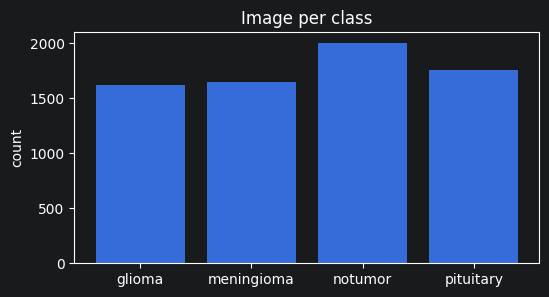

In [27]:
counts = class_distribution(y, list(spec.classes), "(full dataset)")

plt.figure(figsize=(6, 3))
plt.bar(CLASSES, counts)
plt.title("Image per class")
plt.ylabel("count")
plt.show()

## 4. Build tf.data Pipelines
Stratified train/val split + rebalancing strategy (`auto`, `none`, `class_weight`, `augment`).

In [28]:
train_ds, val_ds, class_weight = get_datasets(
    spec,
    batch_size=BATCH_SIZE,
    strategy="auto",
)

def to_one_hot(ds):
    ds = ds.map(lambda x, y: (x, tf.one_hot(y, len(CLASSES))), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_oh = to_one_hot(train_ds)
val_oh = to_one_hot(val_ds)

Duplicates removed: 426 (kept 6597)

Class distribution (train)
  glioma         1134   24.5%  #####################################
  meningioma     1073   23.2%  ###################################
  notumor        1196   25.9%  #######################################
  pituitary      1218   26.4%  ########################################
  imbalance ratio (max/min) = 1.14 -> balanced enough: no rebalancing needed

Class distribution (val)
  glioma          243   24.6%  #####################################
  meningioma      229   23.2%  ###################################
  notumor         255   25.8%  #######################################
  pituitary       261   26.4%  ########################################
  imbalance ratio (max/min) = 1.14 -> balanced enough: no rebalancing needed

Class distribution (test, counts only)
  glioma          243   24.6%  #####################################
  meningioma      229   23.2%  ###################################
  notumor         255 

## 5. Sanity Check (one batch)

In [29]:
for xb, yb in train_ds.take(1):
    print(xb.shape, xb.dtype, yb.shape)
    print("pixel range:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)))

(32, 224, 224, 3) <dtype: 'float32'> (32,)
pixel range: 0.0 - 1.0


## 6. Visualize Samples

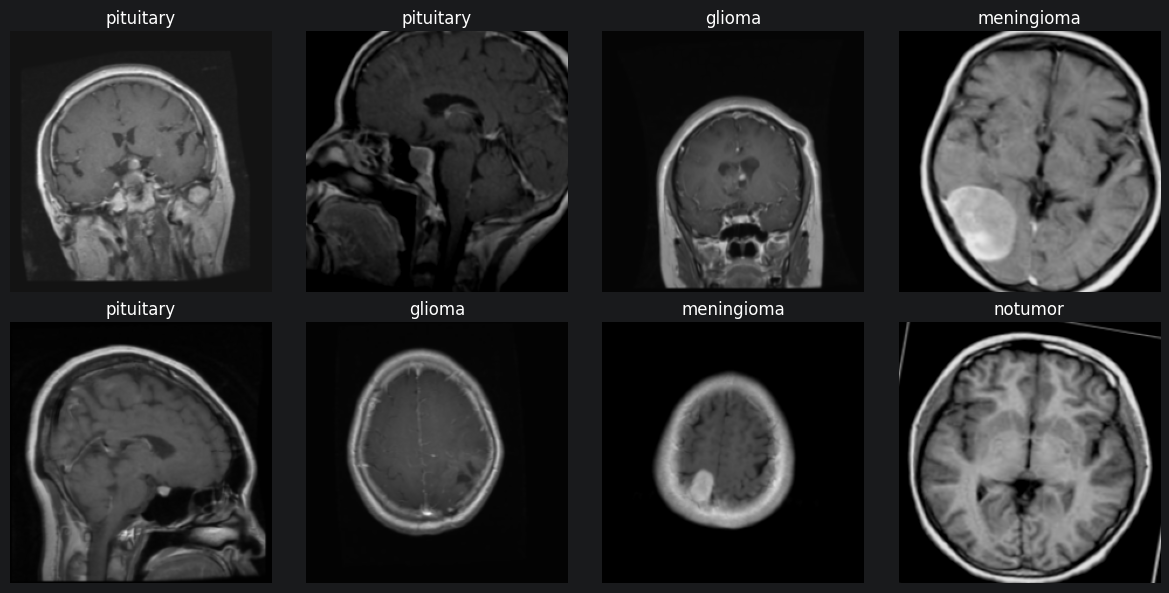

In [30]:
xb, yb = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(xb[i].numpy()[..., ::-1])
    plt.title(CLASSES[int(yb[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 6b. Preview Augmentation
One original (left) and 4 random augmented versions of it.

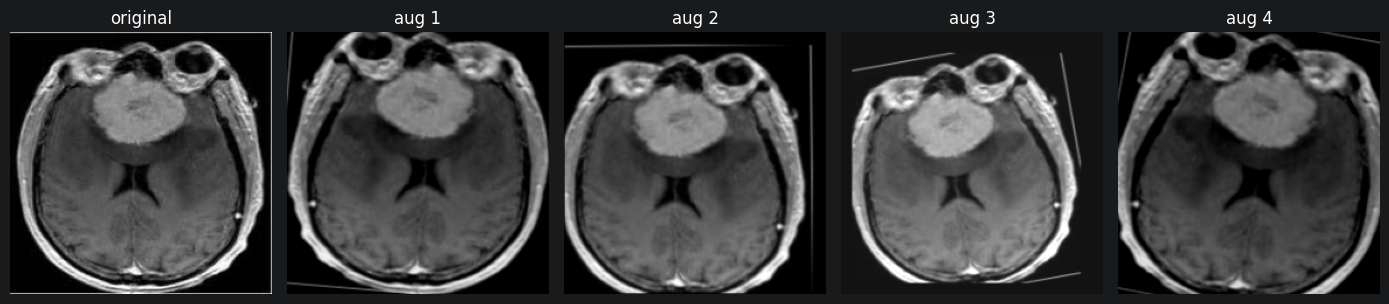

In [31]:
from src.pipeline import build_augmenter

aug = build_augmenter()
img = X[:1].astype("float32")

plt.figure(figsize=(14, 3))
plt.subplot(1, 5, 1)
plt.imshow(X[0][..., ::-1])
plt.title("original")
plt.axis("off")
for i in range(4):
    out = aug(img, training=True)[0].numpy().clip(0, 255).astype("uint8")
    plt.subplot(1, 5, i + 2)
    plt.imshow(out[..., ::-1])
    plt.title(f"aug {i + 1}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Build Model

In [32]:
def conv_block(x, filters):
    x = tf.keras.layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.Conv2D(filters, kernel_size=3,padding="same", use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    return tf.keras.layers.MaxPooling2D()(x)

inputs = tf.keras.Input(shape=(*spec.target_size, 3))
x = inputs
for f in (32, 64, 128, 256):
    x = conv_block(x, f)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(len(CLASSES), activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="mri_cnn")
model.summary()


Model: "mri_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             

 Total params: 1,176,164 (4.49 MB)

 Trainable params: 1,174,244 (4.48 MB)

 Non-trainable params: 1,920 (7.50 KB)

## Architecture diagram

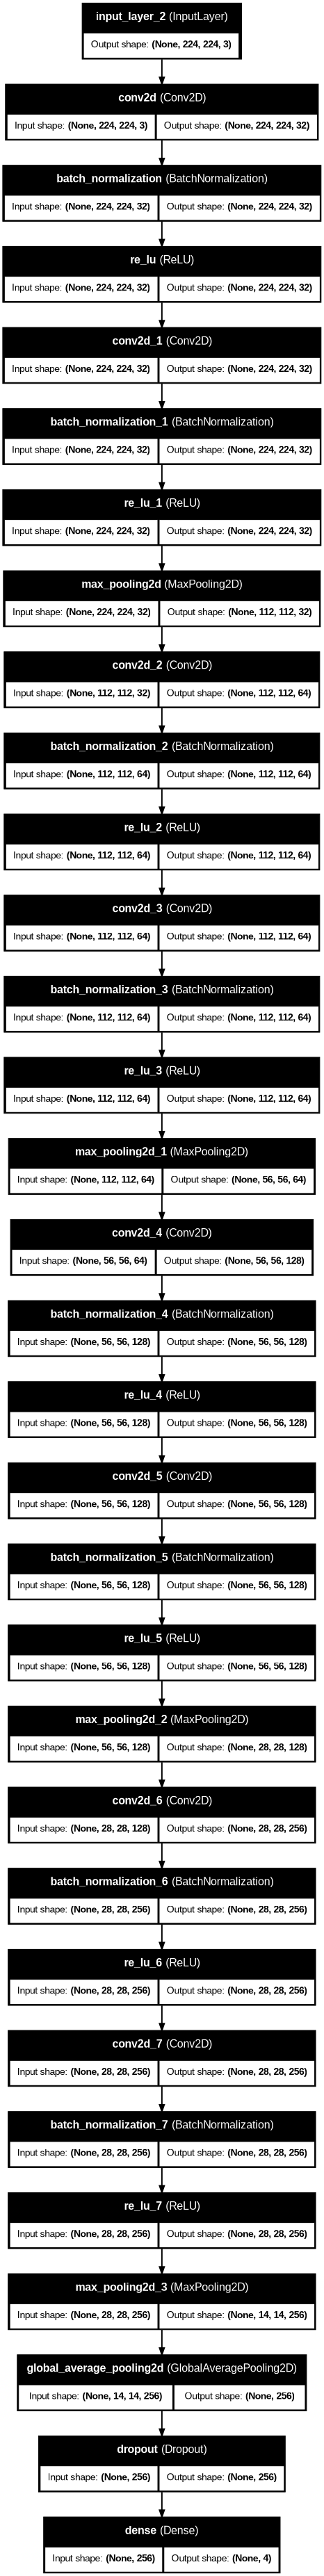

In [33]:
from IPython.display import Image, display

os.makedirs("models", exist_ok=True)

try:
    tf.keras.utils.plot_model(
        model, to_file="models/model.png",
        show_shapes=True, show_layer_names=True, dpi=70,
    )
    display(Image("models/model.png"))
except Exception as e:
    print("plot_model needs pydot + graphviz, skipping:", e)

## 8. Compile Model

In [34]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

## 9. Train

In [36]:
from src.EpochTimer import EpochTimer
import time

os.makedirs("models", exist_ok=True)


timer = EpochTimer()

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
    tf.keras.callbacks.ModelCheckpoint("models/best.keras", monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.BackupAndRestore(backup_dir="backup"),
    timer,
]

start = time.perf_counter()

history = model.fit(
    train_oh,
    validation_data=val_oh,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
)

total = time.perf_counter() - start

print(f"\nTotal training time: {total:.1f} s ({total / 60:.1f} min)")
print(f"Epochs run: {len(timer.times)} | mean per epoch: {np.mean(timer.times):.1f} s "
      f"| first epoch: {timer.times[0]:.1f} s | fastest: {min(timer.times):.1f} s")

Epoch 1/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 70s 480ms/step - accuracy: 0.7410 - loss: 0.6677 - val_accuracy: 0.2520 - val_loss: 4.3981 - learning_rate: 0.0010
Epoch 2/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 70s 480ms/step - accuracy: 0.7966 - loss: 0.5480 - val_accuracy: 0.4170 - val_loss: 2.1383 - learning_rate: 0.0010
Epoch 3/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 71s 485ms/step - accuracy: 0.8180 - loss: 0.4815 - val_accuracy: 0.7409 - val_loss: 0.8061 - learning_rate: 0.0010
Epoch 4/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 69s 477ms/step - accuracy: 0.8472 - loss: 0.4306 - val_accuracy: 0.5951 - val_loss: 1.8763 - learning_rate: 0.0010
Epoch 5/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 71s 487ms/step - accuracy: 0.8580 - loss: 0.3798 - val_accuracy: 0.5719 - val_loss: 1.5902 - learning_rate: 0.0010
Epoch 6/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 70s 483ms/step - accuracy: 0.8870 - loss: 0.3239 - val_accuracy: 0.8188 - val_loss: 0.4765 - learning_rate: 5.0000e-04
Epoch 7/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 70s 479ms/step - accuracy:

## 10. Training Curves

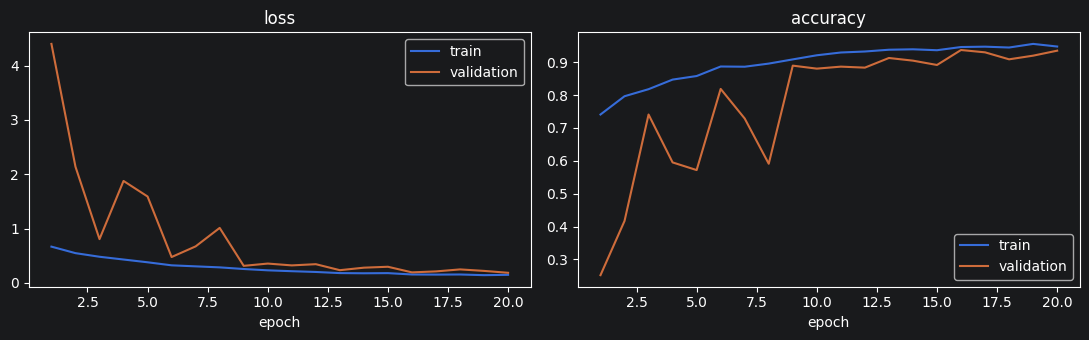

best epoch: 20 of 20
train acc  0.948 | val acc  0.935 | gap +0.013
train loss 0.149 | val loss 0.187 | gap +0.037
verdict: good fit: small gap between train and validation


In [37]:
h = history.history
epochs = np.arange(1, len(h["loss"]) + 1)
best = int(np.argmin(h["val_loss"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, m in zip(ax, ("loss", "accuracy")):
    a.plot(epochs, h[m], label="train")
    a.plot(epochs, h[f"val_{m}"], label="validation")
    a.set_title(m)
    a.set_xlabel("epoch")
    a.legend()
plt.tight_layout()
plt.show()


# overfitting analysis

tr_acc, va_acc = h["accuracy"][best], h["val_accuracy"][best]
tr_loss, va_loss = h["loss"][best], h["val_loss"][best]
acc_gap = tr_acc - va_acc
loss_gap = va_loss - tr_loss

print(f"best epoch: {best + 1} of {len(epochs)}")
print(f"train acc  {tr_acc:.3f} | val acc  {va_acc:.3f} | gap {acc_gap:+.3f}")
print(f"train loss {tr_loss:.3f} | val loss {va_loss:.3f} | gap {loss_gap:+.3f}")

after = len(epochs) - 1 - best
if after > 0:
    print(f"val loss {h['val_loss'][-1] - va_loss:+.3f} vs best, over the {after} epochs after it")

if acc_gap > 0.10:
    verdict = "OVERFITTING: train accuracy is far above validation accuracy"
elif acc_gap > 0.05:
    verdict = "mild overfitting"
elif tr_acc < 0.85 and va_acc < 0.85:
    verdict = "possible UNDERFITTING: both accuracies are low, train longer or use a bigger model"
else:
    verdict = "good fit: small gap between train and validation"
print("verdict:", verdict)


## 11. Evaluate

In [38]:
val_loss, val_acc = model.evaluate(val_oh)
print(f"val loss: {val_loss:.4f} | val accuracy: {val_acc:.4f}")

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9352 - loss: 0.1865 
val loss: 0.1865 | val accuracy: 0.9352


## 12. Per-Class Report
val_ds is not shuffled, so predictions and labels line up.

31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step  
              precision    recall  f1-score   support

      glioma      0.950     0.942     0.946       243
  meningioma      0.898     0.843     0.869       229
     notumor      0.972     0.961     0.966       255
   pituitary      0.918     0.985     0.950       261

    accuracy                          0.935       988
   macro avg      0.934     0.933     0.933       988
weighted avg      0.935     0.935     0.935       988



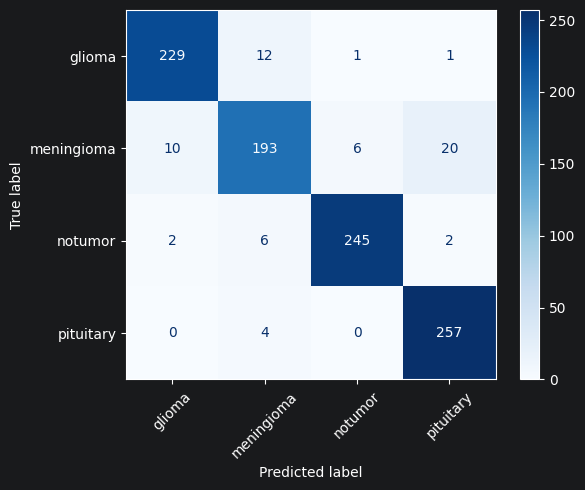

In [39]:
y_true = np.concatenate([yb.numpy() for _, yb in val_ds])
y_pred = np.argmax(model.predict(val_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap="Blues", xticks_rotation=45)
plt.show()

## Confusion Analysis

64 misclassified of 988 (6.5%)
mean confidence: correct 0.947 | wrong 0.719
wrong predictions with confidence > 0.9: 10 of 64

Most frequent confusions (true -> predicted):
   meningioma -> pituitary     20  (8.7% of all true meningioma)
       glioma -> meningioma    12  (4.9% of all true glioma)
   meningioma -> glioma        10  (4.4% of all true meningioma)
      notumor -> meningioma     6  (2.4% of all true notumor)
   meningioma -> notumor        6  (2.6% of all true meningioma)
    pituitary -> meningioma     4  (1.5% of all true pituitary)

tumor predicted as 'notumor' (missed tumors): 7


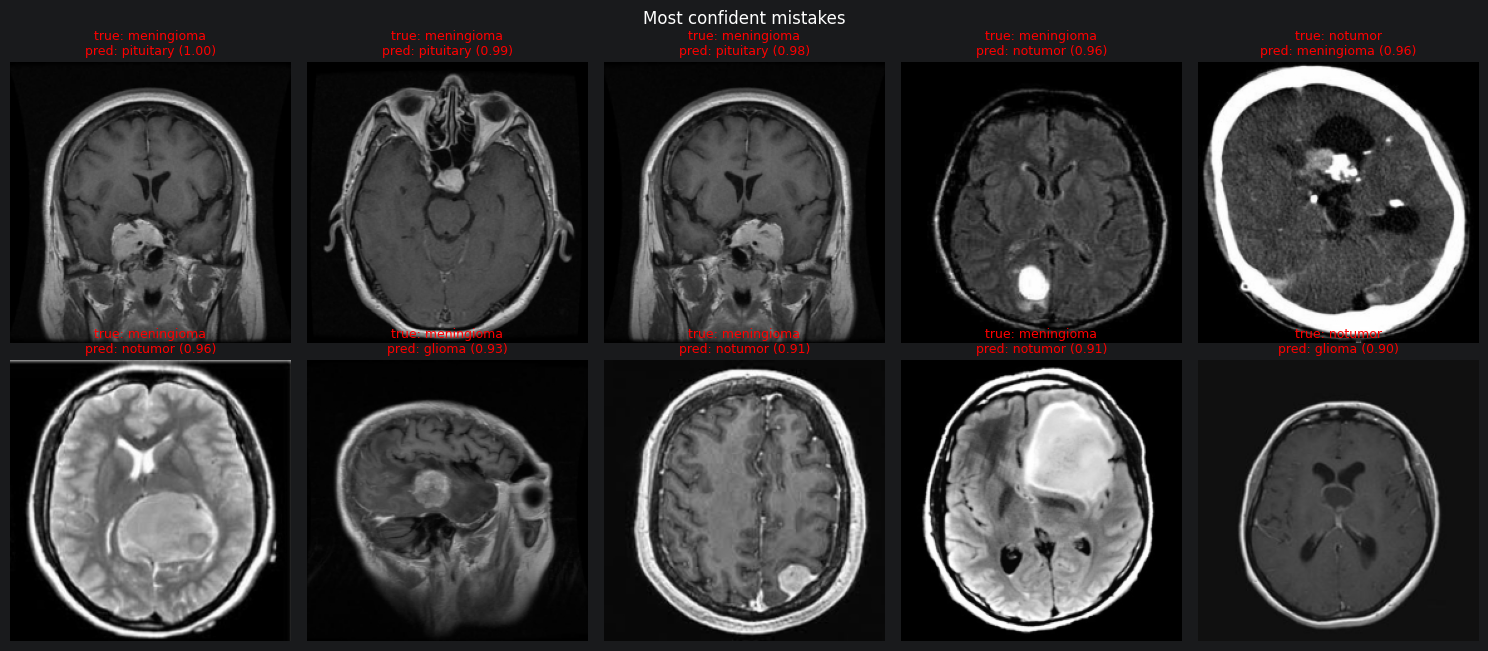

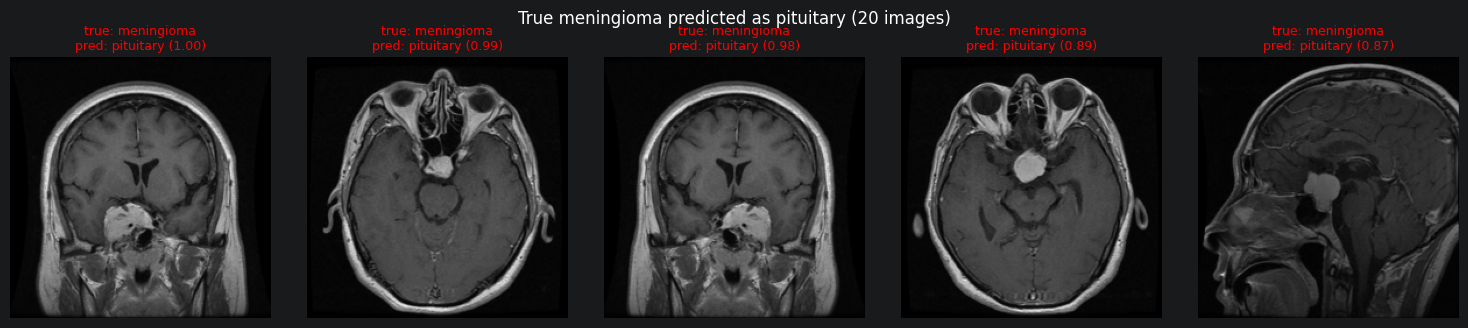

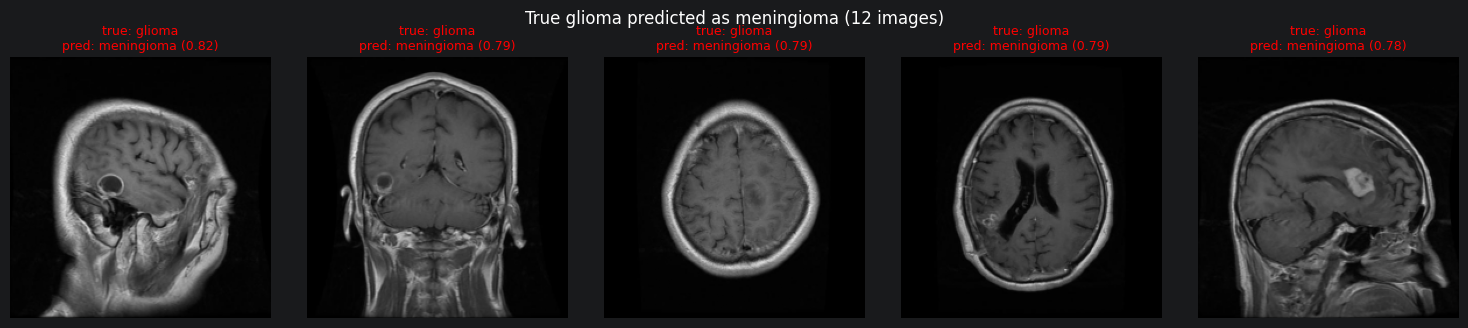

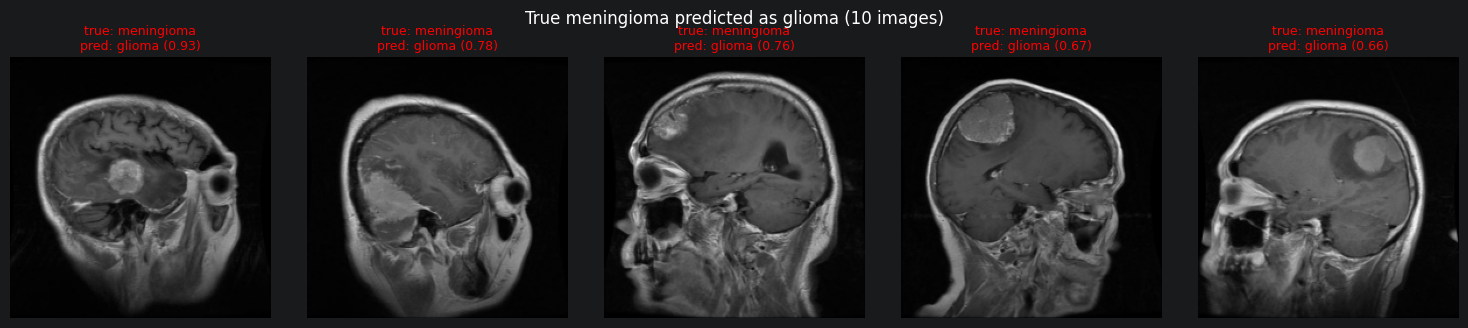

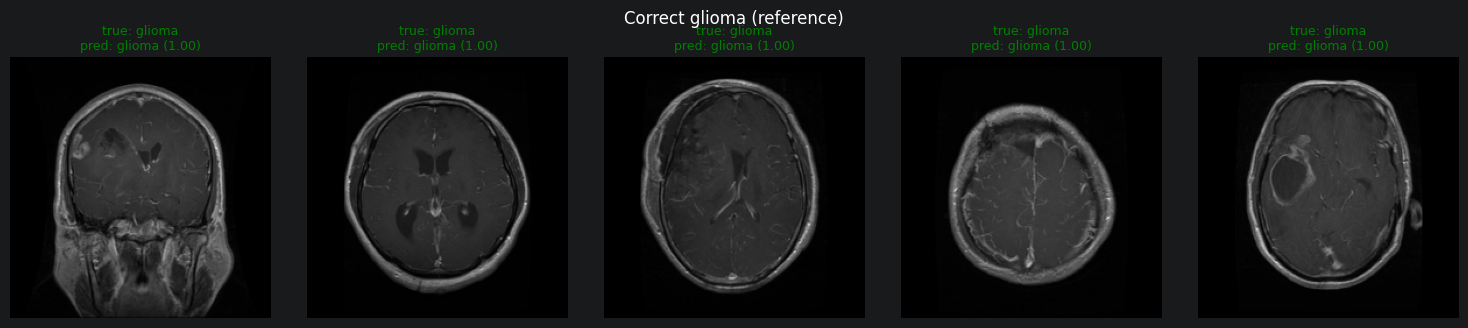

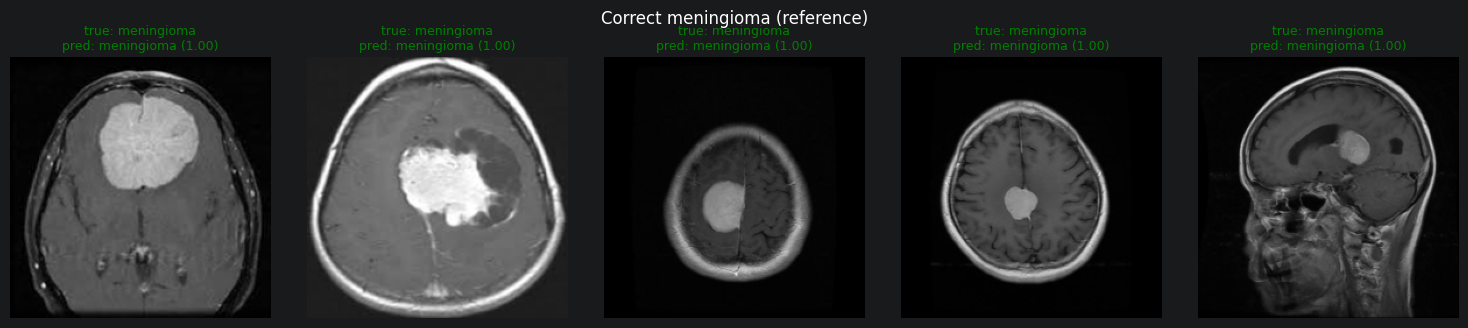

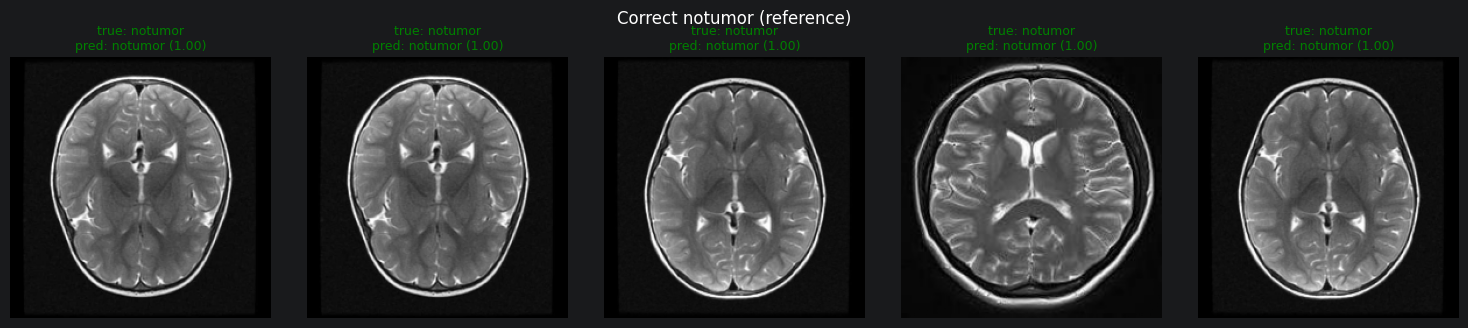

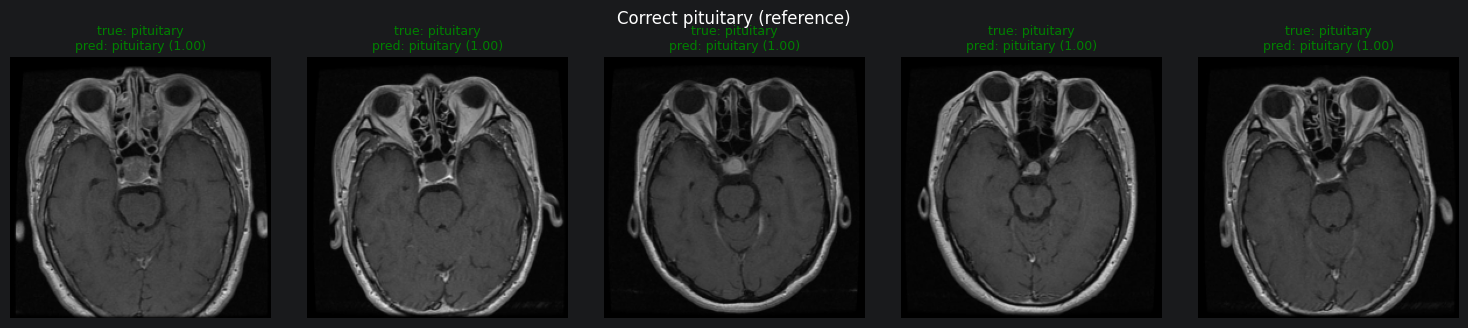

In [40]:
# ---- collect validation images, labels and predictions (validation only: the test set stays untouched) ----
xs, ys = [], []
for xb, yb in val_ds:                       # val_ds is not shuffled, so order is stable
    xs.append(xb.numpy()); ys.append(yb.numpy())
X_val_img = np.concatenate(xs)
y_true = np.concatenate(ys)

probs = model.predict(X_val_img, batch_size=BATCH_SIZE, verbose=0)
y_pred = probs.argmax(axis=1)
conf = probs.max(axis=1)                    # confidence of the predicted class
wrong = np.where(y_pred != y_true)[0]
right = np.where(y_pred == y_true)[0]

print(f"{len(wrong)} misclassified of {len(y_true)} ({100 * len(wrong) / len(y_true):.1f}%)")
if len(wrong):
    print(f"mean confidence: correct {conf[right].mean():.3f} | wrong {conf[wrong].mean():.3f}")
    print(f"wrong predictions with confidence > 0.9: {(conf[wrong] > 0.9).sum()} of {len(wrong)}")

# ---- which classes get confused, most frequent first ----
labels = list(range(len(CLASSES)))
cm = confusion_matrix(y_true, y_pred, labels=labels)
pairs = sorted(((cm[i, j], i, j) for i in labels for j in labels if i != j and cm[i, j] > 0), reverse=True)

print("\nMost frequent confusions (true -> predicted):")
for n, i, j in pairs[:6]:
    print(f"  {CLASSES[i]:>11} -> {CLASSES[j]:<11} {n:>4}  ({100 * n / cm[i].sum():.1f}% of all true {CLASSES[i]})")

missed = sum(cm[i, CLASSES.index("notumor")] for i in labels if CLASSES[i] != "notumor")
print(f"\ntumor predicted as 'notumor' (missed tumors): {missed}")


def show(idx, title, cols=5, max_n=10):
    idx = list(idx)[:max_n]
    if not idx:
        print(f"{title}: none"); return
    rows = int(np.ceil(len(idx) / cols))
    plt.figure(figsize=(3 * cols, 3.3 * rows))
    for k, i in enumerate(idx):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(X_val_img[i][..., ::-1])            # BGR (OpenCV) -> RGB for display
        ok = y_true[i] == y_pred[i]
        plt.title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} ({conf[i]:.2f})",
                  fontsize=9, color="green" if ok else "red")
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# 1) the most confident mistakes
show(wrong[np.argsort(-conf[wrong])], "Most confident mistakes")

# 2) examples of the 3 most frequent confusions
for n, i, j in pairs[:3]:
    idx = np.where((y_true == i) & (y_pred == j))[0]
    show(idx[np.argsort(-conf[idx])], f"True {CLASSES[i]} predicted as {CLASSES[j]} ({n} images)", max_n=5)

# 3) reference: confident correct examples of each class, to compare with the mistakes above
ref = [right[y_true[right] == c][np.argsort(-conf[right[y_true[right] == c]])][:5] for c in labels]
for c, idx in zip(labels, ref):
    show(idx, f"Correct {CLASSES[c]} (reference)", max_n=5)

## 13. Save Model

In [41]:
model.save("models/mri_cnn.keras")
print("saved to models/mri_cnn.keras")

saved to models/mri_cnn.keras


## 14. Final Test

31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.9251 - loss: 0.1934 
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step
TEST loss: 0.1934 | TEST accuracy: 0.9251
              precision    recall  f1-score   support

      glioma      0.954     0.930     0.942       243
  meningioma      0.883     0.821     0.851       229
     notumor      0.976     0.961     0.968       255
   pituitary      0.889     0.977     0.931       261

    accuracy                          0.925       988
   macro avg      0.925     0.922     0.923       988
weighted avg      0.926     0.925     0.925       988



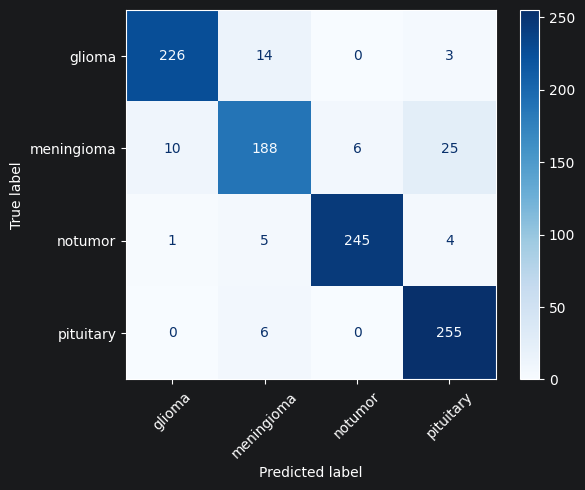

In [42]:
if "test_result" in globals():
    print("Test set already evaluated: showing the stored result, not evaluating again.")
else:
    if "test_ds" not in globals():
        test_ds = get_test_ds(spec)

    test_oh = to_one_hot(test_ds)
    test_loss, test_acc = model.evaluate(test_oh)
    y_true = np.concatenate([yb.numpy() for _, yb in test_ds])
    y_pred = np.argmax(model.predict(test_ds), axis=1)

    test_result = {"loss": float(test_loss), "accuracy": float(test_acc), "y_true": y_true, "y_pred": y_pred}


print(f"TEST loss: {test_loss:.4f} | TEST accuracy: {test_acc:.4f}")

print(classification_report(test_result["y_true"], test_result["y_pred"], target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(
    confusion_matrix(test_result["y_true"], test_result["y_pred"]), display_labels=CLASSES
).plot(cmap="Blues", xticks_rotation=45)
plt.show()

## 15. Predict One Image

data/raw/notumor/Te-no_0132.jpg
{'label': 'notumor', 'confidence': 0.9995420575141907, 'probs': {'glioma': 2.7643265639198944e-05, 'meningioma': 0.00042523679439909756, 'notumor': 0.9995420575141907, 'pituitary': 5.0192752496514e-06}, 'uncertain': False}


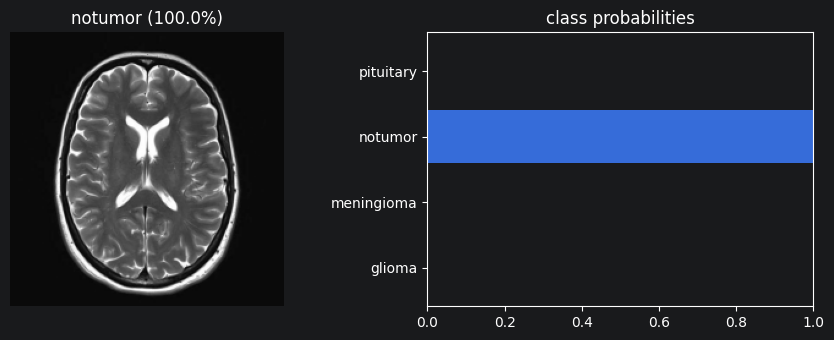

In [46]:
import importlib
import os
import src.predict as sp
importlib.reload(sp)
from src.predict import predict_image, safe_predict, show_prediction

sample_dir = os.path.join(RAW_DIR, CLASSES[2])
sample = os.path.join(sample_dir, sorted(os.listdir(sample_dir))[132])
print(sample)

result = predict_image(sample, model, CLASSES)
print({k: v for k, v in result.items() if k != "image"})
show_prediction(result)
